# 02 — ML Metrics

How to measure a model, and how to pick the metric that matches what its mistakes cost.

## What's in this notebook

- 1\. Choosing a metric by the cost of errors
- 2\. Regression metrics
- 3\. Confusion matrix and the metrics built on it
- 4\. The threshold trade-off
- 5\. Imbalanced data: ROC-AUC vs PR-AUC
- 6\. Log loss and calibration
- 7\. Multiclass averaging: macro, micro, weighted
- 8\. Ranking metrics for search and RAG
- 9\. Appendix: clustering metrics in brief
- 10\. Cheat table
- 11\. Interview questions
- 12\. In my own words

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes, load_breast_cancer, make_classification, make_blobs
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.cluster import KMeans
from sklearn.metrics import (mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error, r2_score,
                             confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
                             balanced_accuracy_score, matthews_corrcoef, classification_report,
                             roc_auc_score, roc_curve, average_precision_score,
                             precision_recall_curve, log_loss, brier_score_loss, ndcg_score, silhouette_score)

# NumPy 2.2 + Apple Accelerate prints harmless "encountered in matmul" RuntimeWarnings
warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)

# 1. CHOOSING A METRIC BY THE COST OF ERRORS

A metric turns predictions into one number, so models can be compared. Pick it by asking what a wrong
prediction costs, then check that the model beats a simple baseline (predict the mean, or the most common class).

| Situation | Costly mistake | Metric to watch |
|---|---|---|
| Fraud, disease screening | missing a real positive (FN) | recall |
| Spam filter, alerts a person must review | a false alarm (FP) | precision |
| Rare positives, both mistakes matter | both | F1, PR-AUC |
| Probabilities used as numbers (expected loss, risk scores) | wrong probabilities | log loss, Brier score |
| Price or demand forecast | large misses | RMSE (typical miss: MAE) |
| Search, recommendations, RAG retrieval | the right item is not near the top | Recall@K, MRR, NDCG |

Choose the metric before training, and report a few guardrail metrics next to the main one
(for example, tune for recall but also report precision).

The loss a model is trained on (log loss, MSE) is often not the metric you report. F1 and Recall@K depend on a
threshold or a cut-off, so gradient descent can't optimise them directly: train on a smooth loss, then tune the
threshold or K for the business metric.

# 2. REGRESSION METRICS

| Metric | Formula | Unit | Read it as |
|---|---|---|---|
| MAE | mean(\|y − ŷ\|) | same as y | the typical miss; every unit of error counts the same |
| MSE | mean((y − ŷ)²) | y² | squares the errors, so big misses dominate; the usual training loss |
| RMSE | √MSE | same as y | MSE back in the target's units; always ≥ MAE |
| R² | 1 − Σ(y − ŷ)² / Σ(y − ȳ)² | none | share of variance explained (not a % of correct predictions); 1 = perfect, 0 = as good as predicting the mean, < 0 = worse |
| MAPE | mean(\|y − ŷ\| / \|y\|) | % | easy to explain; breaks when y is 0, over-weights rows where y is small, favours forecasts that are too low |

```text
errors 10, 10, 10, 10   ->   MAE = 10, RMSE = 10
errors  0,  0,  0, 40   ->   MAE = 10, RMSE = 20      same MAE, but RMSE doubles because of the one big miss
```

Use MAE when every unit of error costs the same, RMSE when big misses are much worse.
Minimising MAE targets the median of y; minimising MSE targets the mean.

MAPE's bias: with non-negative forecasts, an under-forecast can cost at most 100% but an over-forecast has no limit.
**WAPE** = Σ|y − ŷ| / Σ|y| (total error over total actuals) avoids the per-row division and is common in demand forecasting.

On its training data, linear regression's R² never goes down when you add a feature, even a useless one.
On new data it can. The demo adds 40 columns of random noise to the diabetes data.

In [2]:
X, y = load_diabetes(return_X_y=True)                                       # target: disease progression, 25 to 346
X_noisy = np.hstack([X, np.random.default_rng(0).normal(size=(len(X), 40))])  # + 40 columns of pure noise
Xn_train, Xn_test, y_train, y_test = train_test_split(X_noisy, y, test_size=0.3, random_state=42)
X_train, X_test = Xn_train[:, :10], Xn_test[:, :10]                          # the 10 real features

models = {"predict the mean": (DummyRegressor(), X_train, X_test),
          "linear regression": (LinearRegression(), X_train, X_test),
          "+ 40 noise features": (LinearRegression(), Xn_train, Xn_test)}
rows = {}
for name, (model, train, test) in models.items():
    pred = model.fit(train, y_train).predict(test)
    rows[name] = {"train R²": r2_score(y_train, model.predict(train)), "test R²": r2_score(y_test, pred),
                  "MAE": mean_absolute_error(y_test, pred), "RMSE": root_mean_squared_error(y_test, pred),
                  "MAPE": mean_absolute_percentage_error(y_test, pred)}     # sklearn returns a fraction: 0.3 = 30%
print(pd.DataFrame(rows).T.round(3))
print("\nMAPE when one actual value is 0:", mean_absolute_percentage_error([0, 100], [1, 110]))

                     train R²  test R²     MAE    RMSE   MAPE
predict the mean        0.000   -0.006  64.264  73.708  0.612
linear regression       0.524    0.477  41.919  53.120  0.367
+ 40 noise features     0.590    0.356  46.645  58.971  0.413

MAPE when one actual value is 0: 2251799813685248.0


The linear model misses by 41.9 on average (MAE), with RMSE 53.1. Test R² is 0.477: it explains about half the variance.
Predicting the mean gets R² −0.006 on the test set, just below 0, because the training mean is not exactly the test mean.

The 40 noise columns raise training R² from 0.524 to 0.590 but drop test R² to 0.356.
One actual value of 0 makes MAPE explode to 2.25e15, because sklearn divides by a tiny epsilon instead of 0.

Also seen: **adjusted R²** = 1 − (1 − R²)(n − 1) / (n − p − 1), for n rows and p features, penalises extra features.
It is an in-sample statistic: compute it on training data; on a test set compare plain R² or RMSE.
**SMAPE** divides by (|y| + |ŷ|) / 2 instead of |y|, which caps each error at 200%, but it is still undefined when both are 0.

# 3. CONFUSION MATRIX AND THE METRICS BUILT ON IT

A binary classifier makes two kinds of mistake. The confusion matrix counts them
(scikit-learn's layout: rows are the actual class, columns the predicted class):

```text
                      predicted 0    predicted 1
actual 0 (negative)       TN             FP          FP = false alarm (type I error)
actual 1 (positive)       FN             TP          FN = miss (type II error)
```

`confusion_matrix(y_true, y_pred).ravel()` returns `tn, fp, fn, tp` in that order;
`ConfusionMatrixDisplay.from_predictions(y_true, y_pred)` draws it.

| Metric | Formula | Answers | Use when |
|---|---|---|---|
| Accuracy | (TP + TN) / all | how often is it right? | classes are balanced |
| Precision | TP / (TP + FP) | of what we flagged, how much is real? | false alarms are expensive |
| Recall (sensitivity, TPR) | TP / (TP + FN) | of the real positives, how many did we catch? | misses are expensive |
| Specificity (TNR) | TN / (TN + FP) | of the real negatives, how many did we leave alone? | medical tests; FPR = 1 − specificity |
| F1 | 2·P·R / (P + R) = 2TP / (2TP + FP + FN) | one number for P and R together | both mistakes matter |
| Fβ | (1 + β²)·P·R / (β²·P + R) | F1 with recall counted β times as much as precision | F2 when misses cost more, F0.5 when false alarms do |
| Balanced accuracy | (recall + specificity) / 2; multiclass: mean recall per class | accuracy with every class weighted equally | imbalanced data; 0.5 = no skill |
| MCC | (TP·TN − FP·FN) / √((TP+FP)(TP+FN)(TN+FP)(TN+FN)) | correlation between prediction and truth, −1 to 1 | imbalanced data; high only if both classes are handled well, 0 = no skill |

F1 is a harmonic mean, so it stays low if either side is low: precision 1.0 with recall 0.1 gives F1 = 0.18,
not the 0.55 a plain average would give. Precision, recall and F1 never use TN, so a big pool of easy negatives
cannot inflate them. Accuracy can.

In [3]:
data = load_breast_cancer()
X, y = data.data, (data.target == 0).astype(int)                       # 1 = malignant, the class we want to catch
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
pred = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_train, y_train).predict(X_test)

print(confusion_matrix(y_test, pred))
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
P, R, S = tp / (tp + fp), tp / (tp + fn), tn / (tn + fp)
by_hand = {"accuracy": (tp + tn) / (tp + tn + fp + fn), "precision": P, "recall": R, "specificity": S,
           "F1": 2 * P * R / (P + R), "F2": 5 * P * R / (4 * P + R), "balanced accuracy": (R + S) / 2,
           "MCC": (tp * tn - fp * fn) / np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))}
library = {"accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred),
           "recall": recall_score(y_test, pred), "specificity": recall_score(y_test, pred, pos_label=0),
           "F1": f1_score(y_test, pred), "F2": fbeta_score(y_test, pred, beta=2),
           "balanced accuracy": balanced_accuracy_score(y_test, pred), "MCC": matthews_corrcoef(y_test, pred)}
print(f"\nTN={tn}  FP={fp}  FN={fn}  TP={tp}\n")
print(pd.DataFrame({"from the counts": by_hand, "sklearn": library}).round(3))

[[106   1]
 [  4  60]]

TN=106  FP=1  FN=4  TP=60

                   from the counts  sklearn
accuracy                     0.971    0.971
precision                    0.984    0.984
recall                       0.938    0.938
specificity                  0.991    0.991
F1                           0.960    0.960
F2                           0.946    0.946
balanced accuracy            0.964    0.964
MCC                          0.938    0.938


171 test patients, 64 of them malignant. The model misses 4 cancers (FN) and raises 1 false alarm (FP): precision 0.984, recall 0.938.
In screening the 4 misses are the costly mistake, so recall is the number to push up.
The values from the four counts match sklearn. `recall_score(..., pos_label=0)` gives specificity, because specificity is the recall of the negative class.
F2 (0.946) sits below F1 (0.960) because recall is the weaker side and F2 weights it more. MCC is 0.938 and balanced accuracy 0.964.

# 4. THE THRESHOLD TRADE-OFF

Most classifiers output a probability. `predict()` turns it into a label with a threshold of 0.5.
That threshold is a business choice, not part of the model:

- lower threshold → more items flagged → recall goes up, precision goes down
- higher threshold → fewer items flagged → precision goes up, recall goes down

Choose it on a validation set, never the test set, by maximising F1 or, better, by minimising the real cost of
mistakes. If the probabilities are calibrated (section 6), the cheapest threshold is cost_FP / (cost_FP + cost_FN).

Below: a fraud-like dataset with 2% positives, where a missed fraud costs 10 times a false alarm,
so theory says flag anything above 1 / (1 + 10) ≈ 0.09.

In [4]:
X, y = make_classification(n_samples=40000, n_features=10, n_informative=4, n_redundant=0, n_clusters_per_class=1,
                           weights=[0.98], class_sep=0.5, flip_y=0, random_state=0)       # 2% positives ("fraud")
X_train, X_rest, y_train, y_rest = train_test_split(X, y, test_size=0.5, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=42)
model = LogisticRegression().fit(X_train, y_train)
p_val, p_test = model.predict_proba(X_val)[:, 1], model.predict_proba(X_test)[:, 1]


def at_threshold(y_true, p, t, fn_cost=10):
    tn, fp, fn, tp = confusion_matrix(y_true, p >= t).ravel()
    return {"threshold": t, "flagged": tp + fp, "precision": tp / (tp + fp), "recall": tp / (tp + fn),
            "F1": 2 * tp / (2 * tp + fp + fn), "cost": fp + fn_cost * fn}


table = pd.DataFrame([at_threshold(y_val, p_val, t) for t in [0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7]])
best = table.loc[table["cost"].idxmin(), "threshold"]
print("validation set\n", table.round(3).to_string(index=False))
print(f"\ntest set, default 0.5 vs the threshold chosen on validation ({best})")
print(pd.DataFrame([at_threshold(y_test, p_test, t) for t in (0.5, best)]).round(3).to_string(index=False))

validation set
  threshold  flagged  precision  recall    F1  cost
      0.02     1542      0.110   0.850 0.195  1672
      0.05      795      0.192   0.765 0.308  1112
      0.10      427      0.297   0.635 0.405  1030
      0.20      228      0.456   0.520 0.486  1084
      0.30      150      0.560   0.420 0.480  1226
      0.50       65      0.738   0.240 0.362  1537
      0.70       27      0.926   0.125 0.220  1752

test set, default 0.5 vs the threshold chosen on validation (0.1)
 threshold  flagged  precision  recall    F1  cost
       0.5       72      0.736   0.265 0.390  1489
       0.1      411      0.326   0.670 0.439   937


At the default 0.5 the model flags 65 validation cases and catches only 24% of the frauds.
The cheapest threshold in the table is 0.1, close to the 0.09 from theory: recall rises to 0.635, precision falls to 0.297, and the cost drops from 1,537 to 1,030.
On the untouched test set the choice holds up: recall goes from 0.265 to 0.670 and the cost falls from 1,489 to 937 (37% lower).
The best-F1 threshold (0.2) is not the cheapest one, because F1 counts a miss and a false alarm as equally bad.

# 5. IMBALANCED DATA: ROC-AUC vs PR-AUC

With 2% positives, predicting "not fraud" for everything is 98% accurate and useless. Use metrics that a constant
prediction can't game: recall, precision, F1, balanced accuracy (no skill = 0.5) and MCC (no skill = 0).

To compare models without picking a threshold, use a curve. Both curves sweep every threshold, so they judge how well
the scores rank positives above negatives.

| | ROC curve | PR curve |
|---|---|---|
| Plots | TPR (recall) against FPR = FP / (FP + TN) | precision against recall |
| Area | ROC-AUC = chance that a random positive scores higher than a random negative | PR-AUC, usually computed as average precision (AP) |
| No-skill score | 0.5 | the positive rate (0.02 here) |
| Changes with the class ratio | no (TPR and FPR are each computed within one class) | yes |

Why PR-AUC on imbalanced data: FPR divides by all the negatives. With 98% negatives, hundreds of false alarms
are still a small FPR, so the ROC curve looks great. Precision divides by what was flagged, so the same
false alarms show up directly:

```text
10,000 negatives, 200 positives. A model catches 160 (recall 0.80) at FPR 0.02:
false alarms = 0.02 × 10,000 = 200          precision = 160 / (160 + 200) = 0.44
```

When each one misleads:
- ROC-AUC: on heavy imbalance it looks great while precision is poor (above).
- PR-AUC: it depends on the positive rate, so don't compare it across datasets with different class ratios;
  it also ignores how well the negatives are handled.
- Both: they average over all thresholds, including ones you would never use, and neither checks calibration.
  Also report precision and recall at the threshold you deploy.
- An AUC below 0.5 means the scores are ranked backwards (often a flipped label); reversing them gives 1 − AUC.

In [5]:
always_negative = DummyClassifier(strategy="most_frequent").fit(X_train, y_train).predict(X_test)
candidates = {"always 'not fraud'": always_negative, "model at 0.5": p_test >= 0.5, f"model at {best}": p_test >= best}
print(pd.DataFrame({name: {"accuracy": accuracy_score(y_test, pred), "balanced accuracy": balanced_accuracy_score(y_test, pred),
                           "MCC": matthews_corrcoef(y_test, pred), "recall": recall_score(y_test, pred),
                           "F1": f1_score(y_test, pred, zero_division=0)} for name, pred in candidates.items()}).T.round(3))

                    accuracy  balanced accuracy    MCC  recall     F1
always 'not fraud'     0.980              0.500  0.000   0.000  0.000
model at 0.5           0.983              0.632  0.436   0.265  0.390
model at 0.1           0.966              0.821  0.453   0.670  0.439


Accuracy rates the useless constant (0.980) almost level with the model (0.983), and it prefers the 0.5 threshold
over the cheaper 0.1 (0.983 vs 0.966). Balanced accuracy and MCC give the constant 0.5 and 0, and they prefer 0.1 (0.821 and 0.453).

ROC-AUC 0.945   PR-AUC (average precision) 0.498   positive rate 0.020


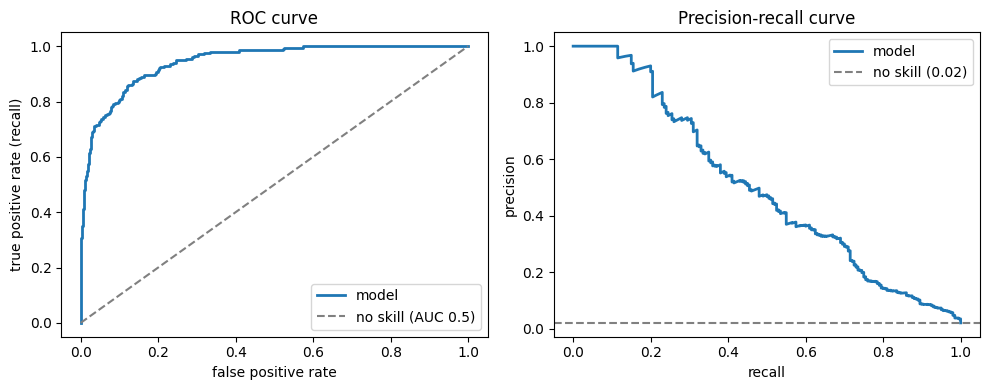

In [6]:
print(f"ROC-AUC {roc_auc_score(y_test, p_test):.3f}   PR-AUC (average precision) {average_precision_score(y_test, p_test):.3f}"
      f"   positive rate {y_test.mean():.3f}")

fpr, tpr, _ = roc_curve(y_test, p_test)
precision, recall, _ = precision_recall_curve(y_test, p_test)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(fpr, tpr, lw=2, label="model")
ax1.plot([0, 1], [0, 1], "--", color="gray", label="no skill (AUC 0.5)")
ax1.set(xlabel="false positive rate", ylabel="true positive rate (recall)", title="ROC curve")
ax2.plot(recall, precision, lw=2, label="model")
ax2.axhline(y_test.mean(), linestyle="--", color="gray", label=f"no skill ({y_test.mean():.2f})")
ax2.set(xlabel="recall", ylabel="precision", title="Precision-recall curve")
for ax in (ax1, ax2):
    ax.legend()
plt.tight_layout()
plt.show()

ROC-AUC is 0.945, which sounds excellent. Average precision is 0.498, which is more honest:
to catch 85% of the frauds (threshold 0.02 on the validation set), precision is 0.11, so 89% of the flagged cases are false alarms.

# 6. LOG LOSS AND CALIBRATION

AUC only looks at the order of the scores. When the probability itself is used (expected-loss calculations,
risk scores shown to people, the threshold rule in section 4), the probabilities also have to be right.

```text
log loss (cross-entropy) = −mean( y·ln(p) + (1 − y)·ln(1 − p) )
Brier score              =  mean( (p − y)² )
```

- Lower is better for both, 0 is perfect. Log loss punishes confident mistakes hard: a real positive
  given p = 0.01 costs −ln 0.01 = 4.6, given p = 0.4 it costs 0.92.
- A model is **calibrated** when its probabilities match reality: of all cases scored about 0.2, about 20% are
  positive. A calibration curve (reliability diagram) compares, per bin, the average prediction with the share of positives.
- `class_weight="balanced"` and oversampling push the rare class's probabilities up. The ranking can stay good,
  but the outputs are no longer probabilities.
- Fix: `CalibratedClassifierCV` with `method="sigmoid"` (Platt scaling) or `"isotonic"` (more flexible, needs more data).
  It fits the calibration on data the model was not trained on (its `cv` folds take care of this).

In [7]:
balanced = LogisticRegression(class_weight="balanced").fit(X_train, y_train)
recalibrated = CalibratedClassifierCV(LogisticRegression(class_weight="balanced"), method="isotonic", cv=5).fit(X_train, y_train)
probs = {"logistic regression": p_test,
         "class_weight='balanced'": balanced.predict_proba(X_test)[:, 1],
         "balanced + isotonic calibration": recalibrated.predict_proba(X_test)[:, 1],
         "always predict the positive rate": np.full(len(y_test), y_train.mean())}
rows = {name: {"ROC-AUC": roc_auc_score(y_test, p), "log loss": log_loss(y_test, p),
               "Brier": brier_score_loss(y_test, p), "mean predicted p": p.mean()} for name, p in probs.items()}
print(pd.DataFrame(rows).T.round(3))
print(f"actual positive rate: {y_test.mean():.3f}\n")

for name in ["logistic regression", "class_weight='balanced'"]:
    observed, predicted = calibration_curve(y_test, probs[name], n_bins=5)    # 5 equal-width bins of predicted p
    print(f"{name}\n  average prediction per bin {predicted.round(2)}\n  share of real positives   {observed.round(2)}")

                                  ROC-AUC  log loss  Brier  mean predicted p
logistic regression                 0.945     0.054  0.014              0.02
class_weight='balanced'             0.960     0.301  0.090              0.17
balanced + isotonic calibration     0.960     0.056  0.016              0.02
always predict the positive rate    0.500     0.098  0.020              0.02
actual positive rate: 0.020

logistic regression
  average prediction per bin [0.01 0.28 0.49 0.66 0.9 ]
  share of real positives   [0.01 0.29 0.53 0.62 0.97]
class_weight='balanced'
  average prediction per bin [0.03 0.29 0.5  0.7  0.92]
  share of real positives   [0.   0.   0.03 0.05 0.23]


Plain logistic regression is already well calibrated: its mean prediction (0.020) matches the positive rate, and each bin's
average prediction is close to its share of positives (0.49 predicted, 0.53 observed).

`class_weight="balanced"` has the best ROC-AUC (0.960) but the worst log loss (0.301, worse than the constant baseline's 0.098).
Its average prediction is 0.17 for a 2% positive rate, and cases it scores 0.92 are positive only 23% of the time.
Isotonic calibration keeps ROC-AUC at 0.960 and brings log loss back down to 0.056.

# 7. MULTICLASS AVERAGING: MACRO, MICRO, WEIGHTED

With more than two classes, precision, recall and F1 are computed per class (that class against the rest).
The `average` argument decides how to combine them:

| `average` | How | Use when |
|---|---|---|
| `macro` | plain mean of the per-class scores | every class matters equally; shows a failing small class |
| `weighted` | mean of the per-class scores, weighted by class size (support) | you want class sizes reflected |
| `micro` | add up TP, FP and FN over all classes, then compute once | you care about overall per-item performance |

For single-label problems, micro precision = micro recall = micro F1 = accuracy. Every wrong prediction is one FP
(for the predicted class) and one FN (for the true class), so both come out as correct / total.
That's why `classification_report` prints an `accuracy` row instead of a micro average.

In [8]:
X, y = make_classification(n_samples=4000, n_features=10, n_informative=4, n_redundant=0, n_classes=3,
                           n_clusters_per_class=1, weights=[0.75, 0.2, 0.05], class_sep=0.8, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
pred = LogisticRegression().fit(X_train, y_train).predict(X_test)

print(classification_report(y_test, pred, digits=3))
for average in ("macro", "weighted", "micro"):
    print(f"{average:>8} F1 = {f1_score(y_test, pred, average=average):.3f}")
print(f"accuracy    = {accuracy_score(y_test, pred):.3f}")

              precision    recall  f1-score   support

           0      0.975     1.000     0.987       895
           1      0.965     0.909     0.936       241
           2      0.727     0.625     0.672        64

    accuracy                          0.962      1200
   macro avg      0.889     0.845     0.865      1200
weighted avg      0.960     0.962     0.960      1200

   macro F1 = 0.865
weighted F1 = 0.960
   micro F1 = 0.962
accuracy    = 0.962


Class 2 is only 5% of the data (64 of 1,200 test rows) and has F1 0.672. Macro F1 (0.865) shows the problem;
weighted F1 (0.960) mostly hides it, because class 2 carries little weight. Micro F1 is 0.962, exactly the accuracy.

# 8. RANKING METRICS FOR SEARCH AND RAG

Search, recommendations and the retrieval step of RAG return a ranked list for each query. These metrics score
the top K of each list against labelled relevant documents, then average over queries. This is how RAG retrieval
is evaluated: collect test questions, label the chunks that answer each one, and score the retriever.

| Metric | For one query | Question it answers |
|---|---|---|
| Precision@K | relevant docs in top K / K | how much of what we return is useful? |
| Recall@K | relevant docs in top K / all relevant docs | did the needed docs make it into the top K? |
| MRR | 1 / rank of the first relevant doc (0 if none), averaged over queries | how high is the first hit? |
| AP@K, MAP | see below | precision over all the relevant docs, rewarding early hits |
| NDCG@K | DCG@K / ideal DCG@K | graded relevance (0 to 3), discounted by position |

```text
DCG@K  = Σ (i = 1..K) rel_i / log2(i + 1)        some libraries use 2^rel − 1 as the gain instead of rel
NDCG@K = DCG@K / IDCG@K                          IDCG = DCG of the best possible order, so 1.0 = perfect
AP@K   = (1 / min(K, R)) · Σ Precision@i over the positions i ≤ K that hold a relevant doc
         R = the total number of relevant docs for the query; standard AP (no cut-off) divides by R
MAP    = mean of AP over all queries
```

For RAG, K is the number of chunks put into the prompt. Recall@K comes first: if the chunk with the answer is not
in the top K, the LLM cannot use it. MRR and NDCG show how high it ranked, which matters once a reranker keeps
only the top few. Hit rate@K (share of queries with at least one relevant doc in the top K) equals Recall@K when
each query has exactly one relevant doc. Answer quality (is the answer correct and grounded in the retrieved text?)
is evaluated separately, often with an LLM as the judge.

In [9]:
# For each query: the doc ids the retriever returned (best first), and the labelled relevant docs with a grade (3 = best)
queries = {"reset my password": (["d3", "d1", "d7", "d2", "d9"], {"d1": 3, "d2": 1, "d5": 2}),
           "refund policy":     (["d4", "d8", "d6", "d2", "d1"], {"d4": 3}),
           "api rate limits":   (["d6", "d5", "d9", "d3", "d7"], {"d7": 2, "d8": 3})}


def precision_at_k(ranked, rel, k): return sum(d in rel for d in ranked[:k]) / k
def recall_at_k(ranked, rel, k):    return sum(d in rel for d in ranked[:k]) / len(rel)
def reciprocal_rank(ranked, rel):   return next((1 / i for i, d in enumerate(ranked, 1) if d in rel), 0.0)


def average_precision_at_k(ranked, rel, k):
    hits, total = 0, 0.0
    for i, d in enumerate(ranked[:k], 1):
        if d in rel:
            hits += 1
            total += hits / i                       # precision at each position that holds a relevant doc
    return total / min(k, len(rel))                 # divide by all relevant docs (capped at k), not only the ones found


def ndcg_at_k(ranked, rel, k):
    dcg = sum(rel.get(d, 0) / np.log2(i + 1) for i, d in enumerate(ranked[:k], 1))
    idcg = sum(g / np.log2(i + 1) for i, g in enumerate(sorted(rel.values(), reverse=True)[:k], 1))
    return dcg / idcg


scores = pd.DataFrame({q: {"P@3": precision_at_k(r, rel, 3), "R@3": recall_at_k(r, rel, 3), "R@5": recall_at_k(r, rel, 5),
                           "RR": reciprocal_rank(r, rel), "AP@5": average_precision_at_k(r, rel, 5),
                           "NDCG@5": ndcg_at_k(r, rel, 5)} for q, (r, rel) in queries.items()}).T
scores.loc["mean over queries"] = scores.mean()
print(scores.round(3))

docs = [f"d{i}" for i in range(1, 10)]                # sklearn needs a grade and a score for every doc
ranked, rel = queries["reset my password"]
print("\nsklearn ndcg_score for 'reset my password':",
      round(ndcg_score([[rel.get(d, 0) for d in docs]], [[5 - ranked.index(d) if d in ranked else 0 for d in docs]], k=5), 3))

                     P@3    R@3    R@5     RR   AP@5  NDCG@5
reset my password  0.333  0.333  0.667  0.500  0.333   0.488
refund policy      0.333  1.000  1.000  1.000  1.000   1.000
api rate limits    0.000  0.000  0.500  0.200  0.100   0.182
mean over queries  0.222  0.444  0.722  0.567  0.478   0.556

sklearn ndcg_score for 'reset my password': 0.488


Recall grows with K: 0.444 at K = 3, 0.722 at K = 5. With only 3 chunks in the prompt, the "api rate limits" question gets
none of its relevant docs; its first hit is at rank 5 (RR 0.2).
"reset my password" found 2 of its 3 relevant docs. Dividing by the 2 found would give AP 0.5 instead of 0.333 and hide that d5 was
never retrieved. Its NDCG (0.488) matches sklearn's `ndcg_score`.

# 9. APPENDIX: CLUSTERING METRICS IN BRIEF

Without labels, a clustering is judged by its shape: tight clusters, far apart.

- **Silhouette** (−1 to 1, higher is better). For each point, s = (b − a) / max(a, b), where a is the mean distance
  to its own cluster and b the mean distance to the nearest other cluster. Near 1 = well inside its cluster,
  near 0 = on a boundary, negative = probably in the wrong cluster. The score is the mean over all points.
- Davies-Bouldin (lower is better) and Calinski-Harabasz (higher is better) measure the same idea in other ways.
- With true labels: adjusted Rand index (ARI) or normalized mutual information (NMI).
- A good score means clean geometry, not useful segments. Check the clusters against the business question.

In [10]:
X, _ = make_blobs(n_samples=600, centers=4, cluster_std=1.0, random_state=42)
for k in range(2, 7):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    print(f"k = {k}: silhouette = {silhouette_score(X, labels):.3f}")

k = 2: silhouette = 0.591
k = 3: silhouette = 0.757
k = 4: silhouette = 0.788
k = 5: silhouette = 0.690
k = 6: silhouette = 0.560


Silhouette peaks at k = 4 (0.788), the number of blobs the data was made from.

# 10. CHEAT TABLE

| Metric | sklearn | Better | No-skill score |
|---|---|---|---|
| MAE / RMSE | `mean_absolute_error`, `root_mean_squared_error` | lower | the error of always predicting the median / mean |
| R² | `r2_score` | higher (max 1) | 0 (predict the mean) |
| MAPE | `mean_absolute_percentage_error` (a fraction, not %) | lower | — |
| Accuracy | `accuracy_score` | higher | the share of the most common class |
| Precision / recall / F1 / Fβ | `precision_score`, `recall_score`, `f1_score`, `fbeta_score` | higher | flag everything: recall 1, precision = positive rate |
| Balanced accuracy | `balanced_accuracy_score` | higher | 0.5 (binary) |
| MCC | `matthews_corrcoef` | higher (max 1) | 0 |
| ROC-AUC | `roc_auc_score` | higher | 0.5 |
| PR-AUC | `average_precision_score` | higher | the positive rate |
| Log loss | `log_loss` | lower | entropy of the positive rate (ln 2 = 0.693 for 50/50) |
| Brier score | `brier_score_loss` | lower | p·(1 − p) for positive rate p (0.25 for 50/50) |
| NDCG | `ndcg_score` | higher | — |
| Silhouette | `silhouette_score` | higher | — |

# 11. INTERVIEW QUESTIONS

### Q1. Explain how you choose an evaluation metric in 30 seconds.
I start from what a mistake costs. If misses are expensive (fraud, screening) I watch recall; if false alarms are
expensive I watch precision; F1 or PR-AUC when both matter and positives are rare. I use log loss when the
probabilities themselves are used, MAE or RMSE for regression, and Recall@K, MRR or NDCG for search and RAG retrieval.
I always compare with a simple baseline and choose the threshold on validation data.

### Q2. MAE vs MSE vs RMSE?
MAE is the typical miss in the target's units; every unit of error counts the same. MSE squares the errors, so big
misses dominate; it is the usual training loss, but its unit is squared. RMSE = √MSE is back in the target's units
and is always ≥ MAE; a big gap between the two means a few large misses.

### Q3. What does R² mean? Can it be negative? Why adjusted R²?
The share of the target's variance the model explains, compared with always predicting the mean. It is not a
percentage of correct predictions. It is 0 for the mean baseline and negative on test data when the model does worse.
On training data it never drops when you add a feature, so adjusted R² penalises the feature count. Adjusted R² is
an in-sample statistic; on test data, compare plain R² or RMSE.

### Q4. What is wrong with MAPE?
It divides by the actual value, so it explodes when y is 0 or near 0, gives most weight to rows with small y, and
favours low forecasts (an under-forecast costs at most 100%, an over-forecast has no limit).
Alternatives: WAPE, SMAPE, or MAE in business units.

### Q5. Precision vs recall?
Precision = TP / (TP + FP): of what we flagged, how much was right. Recall = TP / (TP + FN): of the real positives,
how many we caught. Spam filter → precision (don't hide real email). Cancer screening → recall (don't miss a patient).
A false positive is a type I error, a false negative a type II error.

### Q6. Why is F1 a harmonic mean, and what is Fβ?
The harmonic mean is pulled towards the smaller value, so a model can't get a good F1 by maxing out only precision
or only recall (P = 1.0 with R = 0.1 gives F1 = 0.18). Fβ counts recall β times as much as precision:
F2 when misses cost more, F0.5 when false alarms do.

### Q7. Sensitivity vs specificity?
Sensitivity is recall, TP / (TP + FN): how many real positives the test catches. Specificity is TN / (TN + FP):
how many real negatives it correctly clears. The ROC curve plots sensitivity against 1 − specificity.

### Q8. Why is accuracy misleading on imbalanced data, and what do you use instead?
With 2% positives, "always negative" scores 98% accuracy and catches nothing. Use recall, precision, F1 and PR-AUC,
or a single number a constant prediction can't game: balanced accuracy (0.5 for no skill) or MCC (0 for no skill).

### Q9. What does ROC-AUC measure, and what does an AUC below 0.5 mean?
The probability that a random positive gets a higher score than a random negative: 0.5 is random, 1.0 is perfect.
It measures ranking across all thresholds, not accuracy at one threshold, and says nothing about calibration.
Below 0.5 the scores are ranked backwards, often because of a flipped label; reversing them gives 1 − AUC.

### Q10. ROC-AUC or PR-AUC for fraud with 1% positives? When does each mislead?
PR-AUC. FPR divides by the huge number of negatives, so many false alarms barely move the ROC curve; precision
counts them directly. The PR-AUC baseline is the positive rate (0.01), not 0.5. In section 5, ROC-AUC was 0.945 while average precision was 0.498.
PR-AUC in turn can't be compared across datasets with different positive rates, and neither curve checks calibration
or the threshold you actually deploy.

### Q11. How do you choose the classification threshold?
On a validation set: sweep thresholds and take the one with the lowest business cost (cost_FN × FN + cost_FP × FP),
or the one that meets a constraint such as "recall ≥ 0.9". With calibrated probabilities the cheapest threshold is
cost_FP / (cost_FP + cost_FN). The default 0.5 is rarely right on imbalanced data.

### Q12. What are log loss and calibration?
Log loss is the mean of −ln(probability given to the true class), so confident mistakes are punished hard.
A model is calibrated when its predicted probabilities match observed frequencies. Two models can rank equally well
and have very different log loss; class weighting often breaks calibration. Fix it with Platt scaling or isotonic
regression fitted on held-out data.

### Q13. Macro vs micro vs weighted F1?
Macro averages the per-class F1 equally, so a weak small class shows up. Weighted averages by class size.
Micro pools all decisions; for single-label problems it equals accuracy.

### Q14. Precision@K, Recall@K, MRR, MAP or NDCG: which one when?
Precision@K when only the visible top K matters; Recall@K when relevant items must not be missed (the chunks in a RAG
prompt); MRR when there is one right answer and its rank matters; MAP when several items are relevant (yes/no labels);
NDCG when relevance is graded.

### Q15. How do you evaluate the retrieval step of a RAG system?
Build a labelled set of questions with the chunks that answer them, then measure Recall@K (is the answer among the
K chunks sent to the LLM?), MRR (how high is the first relevant chunk?) and NDCG when relevance is graded.
Evaluate the generated answers separately, for example with an LLM judge.

# 12. IN MY OWN WORDS

Write this from memory, without looking above:

- How I choose a metric:
- Precision vs recall, with one example each:
- Why PR-AUC on imbalanced data:
- When calibration matters:
- How I would evaluate RAG retrieval: